# 02 — Reviewing tag-combo effects

Results of `stp analyze`. For each tag pair or triple:

- **score**: empirical-Bayes positive-review score (percentage points), averaged per developer
- **effect**: how much the combo's games beat (+) or miss (−) what the additive tag model predicts
- the CI, p-value and BH q-value use **developers** as the unit, so a studio's 20-game series counts once

This notebook checks that the top results are real, not artifacts, before they go on the website.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

con = duckdb.connect("../data/analysis.duckdb", read_only=True)
pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(80)
plt.rcParams.update(
    {"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False}
)

con.execute("""
CREATE TEMP VIEW v AS
SELECT t1n.name || ' + ' || t2n.name || COALESCE(' + ' || t3n.name, '') AS combo, c.*
FROM combos c JOIN tags t1n ON t1n.tagid = c.t1 JOIN tags t2n ON t2n.tagid = c.t2
LEFT JOIN tags t3n ON t3n.tagid = c.t3
""")


def q(sql, params=None):
    return con.sql(sql, params=params).pl()


q("SELECT * FROM analysis_info")

analyzed_at,n_games,prior_alpha,prior_beta,ridge_alpha,r2,cv_r2,min_support,min_devs,ci_level,synonym_threshold
str,i64,f64,f64,i64,f64,f64,i64,i64,f64,f64
"""2026-11-18T17:27:10.732953+00:00""",59853,5.577368,1.530545,10,0.305931,0.295423,15,5,0.9,0.5


## 1. Model and scores

The prior is weak (about 7 pseudo-reviews), so only very small games are pulled noticeably toward the 78.5% mean. The additive model explains about 30% of the variance in (logit) scores, with almost no overfitting (CV R² ≈ in-sample R²).

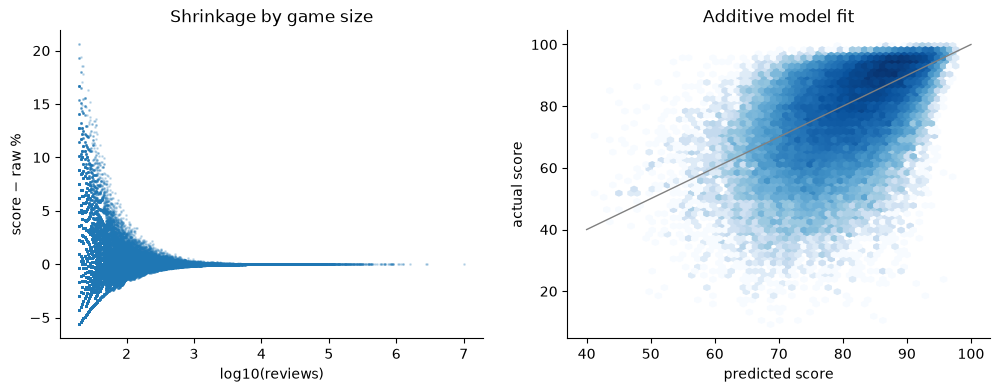

In [2]:
s = q(
    "SELECT g.review_count, g.pct_positive, s.score, s.predicted FROM games g JOIN game_scores s USING (appid)"
)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(np.log10(s["review_count"]), s["score"] - s["pct_positive"], s=1, alpha=0.2)
ax[0].set(xlabel="log10(reviews)", ylabel="score − raw %", title="Shrinkage by game size")
ax[1].hexbin(s["predicted"], s["score"], gridsize=60, bins="log", cmap="Blues")
ax[1].plot([40, 100], [40, 100], c="gray", lw=1)
ax[1].set(xlabel="predicted score", ylabel="actual score", title="Additive model fit")
plt.show()

Strongest single-tag effects (ridge coefficients, logit scale; tags with 100+ developers):

In [3]:
t = q(
    "SELECT name, n_games, n_devs, round(mean_score, 1) AS score, round(coef, 3) AS coef FROM tag_stats WHERE n_devs >= 100"
)
pl.concat([t.sort("coef", descending=True).head(10), t.sort("coef").head(10)])

name,n_games,n_devs,score,coef
str,i64,i64,f64,f64
"""Sokoban""",289,242,89.7,0.42
"""Traditional Roguelike""",116,107,84.3,0.337
"""Boomer Shooter""",292,259,85.4,0.324
"""Faith""",176,137,86.2,0.315
"""Classic""",739,397,82.7,0.292
"""Moddable""",300,271,81.5,0.241
"""LGBTQ+""",1435,959,84.2,0.238
"""Cats""",874,551,87.7,0.233
"""Score Attack""",559,509,85.2,0.229


## 2. Funnel plot

Effect against number of developers. Real effects should be visible outside the noise funnel. The funnel narrowing as n grows is what the CIs encode.

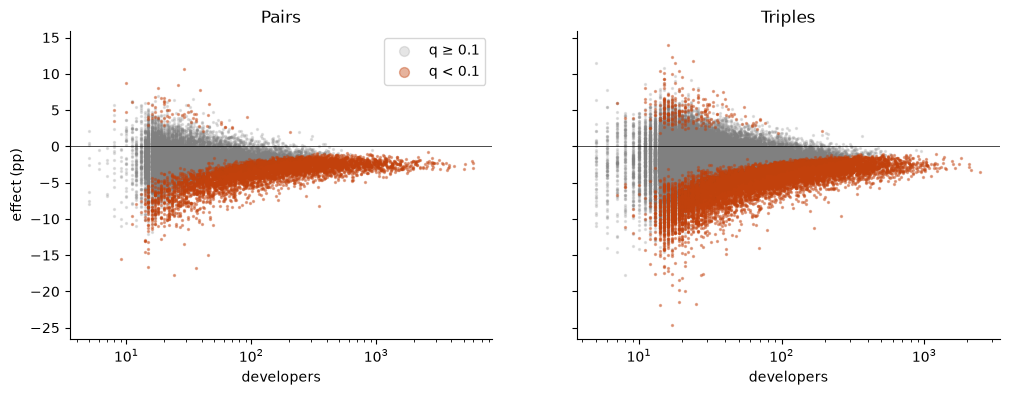

In [4]:
c = q("SELECT size, n_devs, effect, q_value FROM combos WHERE NOT has_synonym")
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, size in zip(ax, (2, 3), strict=True):
    d = c.filter(pl.col("size") == size)
    sig = d["q_value"] < 0.1
    a.scatter(
        d["n_devs"].filter(~sig),
        d["effect"].filter(~sig),
        s=2,
        alpha=0.2,
        c="gray",
        label="q ≥ 0.1",
    )
    a.scatter(
        d["n_devs"].filter(sig),
        d["effect"].filter(sig),
        s=2,
        alpha=0.4,
        c="#c2410c",
        label="q < 0.1",
    )
    a.set(xscale="log", xlabel="developers", title=f"{'Pairs' if size == 2 else 'Triples'}")
    a.axhline(0, c="black", lw=0.5)
ax[0].set_ylabel("effect (pp)")
ax[0].legend(markerscale=5)
plt.show()

## 3. Top and bottom combos

Ranked by the CI bound nearest zero (lower bound for positive effects, upper bound for negative), with synonym pairs excluded.

In [5]:
cols = "combo, n_games, n_devs, round(mean_score, 1) AS score, round(mean_predicted, 1) AS predicted, round(effect, 1) AS effect, round(ci_low, 1) AS ci_low, round(ci_high, 1) AS ci_high, round(q_value, 3) AS q"
q(f"SELECT {cols} FROM v WHERE size = 2 AND NOT has_synonym ORDER BY ci_low DESC LIMIT 15")

combo,n_games,n_devs,score,predicted,effect,ci_low,ci_high,q
str,i64,i64,f64,f64,f64,f64,f64,f64
"""Massively Multiplayer + Loot""",29,29,72.5,61.9,10.6,5.8,15.5,0.007
"""Board Game + Incremental""",21,17,86.6,79.8,6.8,4.1,9.5,0.004
"""Realistic + Incremental""",28,26,80.0,71.5,8.5,4.1,12.8,0.017
"""MMORPG + Loot""",42,39,73.5,65.7,7.8,3.8,11.8,0.015
"""Horror + Medieval""",20,20,85.4,79.4,6.1,3.5,8.6,0.006
"""Tower Defense + VR""",21,19,82.8,76.2,6.7,3.4,9.9,0.015
"""Board Game + Realistic""",20,20,82.1,75.4,6.7,3.2,10.2,0.022
"""4X + Classic""",18,11,87.7,81.6,6.1,3.0,9.2,0.029
"""Crafting + Dialogue Heavy""",16,16,89.5,83.8,5.7,2.9,8.5,0.018


In [6]:
q(f"SELECT {cols} FROM v WHERE size = 2 AND NOT has_synonym ORDER BY ci_high LIMIT 15")

combo,n_games,n_devs,score,predicted,effect,ci_low,ci_high,q
str,i64,i64,f64,f64,f64,f64,f64,f64
"""Trading + Incremental""",37,36,55.7,72.4,-16.7,-21.1,-12.4,0.0
"""RPG + Desktop Companion""",25,24,64.5,82.3,-17.8,-24.7,-10.9,0.002
"""Trading + Idler""",46,45,59.5,74.5,-15.0,-19.9,-10.1,0.0
"""Romance + VR""",32,29,65.6,79.0,-13.4,-17.7,-9.2,0.0
"""Loot + Desktop Companion""",15,15,63.5,80.2,-16.7,-25.2,-8.2,0.022
"""Board Game + Anime""",59,49,71.6,82.4,-10.8,-14.2,-7.3,0.0
"""Free to Play + Incremental""",387,347,68.6,76.8,-8.2,-9.4,-7.0,0.0
"""Crafting + Hidden Object""",15,15,64.2,77.4,-13.2,-19.4,-7.0,0.014
"""Realistic + Fishing""",24,19,64.0,76.8,-12.8,-19.1,-6.6,0.015


In [7]:
q(f"SELECT {cols} FROM v WHERE size = 3 AND NOT has_synonym ORDER BY ci_low DESC LIMIT 15")

combo,n_games,n_devs,score,predicted,effect,ci_low,ci_high,q
str,i64,i64,f64,f64,f64,f64,f64,f64
"""RPG + Massively Multiplayer + Isometric""",16,16,77.3,63.4,14.0,8.0,19.9,0.017
"""Action + Casual + MMORPG""",18,17,76.8,64.4,12.4,7.6,17.1,0.009
"""Casual + Realistic + Incremental""",21,19,82.2,71.8,10.4,6.6,14.1,0.005
"""RPG + Massively Multiplayer + Loot""",24,24,73.1,61.3,11.8,6.4,17.2,0.018
"""Free to Play + Violent + Nudity""",20,20,80.1,70.6,9.6,6.4,12.8,0.002
"""Free to Play + Gore + Sexual Content""",16,15,83.1,73.0,10.2,6.4,13.9,0.008
"""Survival + Life Sim + Management""",15,14,84.0,73.6,10.4,6.3,14.5,0.012
"""Psychological Horror + Sci-fi + Dark""",15,15,92.0,84.0,8.0,5.6,10.4,0.002
"""Action + Open World + Loot""",15,15,80.7,72.2,8.4,5.4,11.5,0.007


In [8]:
q(f"SELECT {cols} FROM v WHERE size = 3 AND NOT has_synonym ORDER BY ci_high LIMIT 15")

combo,n_games,n_devs,score,predicted,effect,ci_low,ci_high,q
str,i64,i64,f64,f64,f64,f64,f64,f64
"""Free to Play + Casual + Trading""",19,19,55.8,77.2,-21.4,-27.2,-15.6,0.0
"""Casual + Trading + Idler""",26,25,55.1,76.8,-21.7,-28.5,-14.8,0.001
"""Casual + Trading + Incremental""",22,21,55.1,75.0,-20.0,-25.3,-14.6,0.0
"""RPG + Trading + Idler""",17,17,51.3,75.9,-24.6,-34.8,-14.4,0.014
"""Romance + Sexual Content + VR""",19,17,56.9,74.5,-17.6,-21.7,-13.5,0.0
"""Free to Play + Colorful + Idler""",28,28,61.3,78.9,-17.6,-22.1,-13.2,0.0
"""Free to Play + Trading + Idler""",19,19,56.1,75.9,-19.8,-26.4,-13.2,0.002
"""Romance + Nudity + VR""",17,15,56.5,74.0,-17.5,-22.2,-12.8,0.001
"""Free to Play + Point & Click + Colorful""",34,27,66.6,84.3,-17.7,-22.8,-12.5,0.0


## 4. Spot checks: which games are behind a combo?

If one developer, franchise or near-duplicate series dominates, the result isn't a genre insight.

In [9]:
def games_in(*names, limit=15):
    return q(
        f"""
        WITH ids AS (SELECT tagid FROM tags WHERE name IN ({", ".join("?" * len(names))}))
        SELECT g.name, g.developer, g.review_count, g.pct_positive, round(s.resid, 1) AS resid
        FROM games g JOIN game_scores s USING (appid) JOIN game_tags gt USING (appid)
        WHERE gt.relevant AND gt.tagid IN (SELECT tagid FROM ids)
        GROUP BY ALL HAVING COUNT(*) = {len(names)}
        ORDER BY g.review_count DESC LIMIT {limit}
    """,
        list(names),
    )


games_in("Massively Multiplayer", "Loot")

name,developer,review_count,pct_positive,resid
str,str,i64,i64,f64
"""SAND: Raiders of Sophie""","""Hologryph""",12762,49,-23.0
"""SpiritVale""","""Baikun Interactive""",5031,47,-25.1
"""Winds of Valen""","""Fiery Dog Games""",1069,68,-3.1
"""Gangs of Space""","""Little Big MMO""",433,75,16.2
"""君临传奇之风起云涌""","""君临传奇之风起云涌""",267,82,10.1
"""Idle Hacking: An Inaction RPG""","""GigaForge Games""",264,79,13.0
"""Embers Adrift""","""Stormhaven Studios""",249,69,2.1
"""奇兽杂货铺""","""Aiyaha Games""",164,58,0.4
"""Dransik""","""Iron Will Games, LLC""",135,68,11.3


In [10]:
games_in("Tower Defense", "VR")

name,developer,review_count,pct_positive,resid
str,str,i64,i64,f64
"""Out of Ammo""","""RocketWerkz""",700,84,11.6
"""Elven Assassin""","""Wenkly Studio Sp. z o.o.""",633,84,11.2
"""Cosmic Trip""","""Funktronic Labs""",409,87,8.9
"""Castle Must Be Mine""","""TheMiddleGray""",227,90,17.2
"""Kittypocalypse""","""Bolverk Games""",193,88,7.7
"""In Your Face TD""","""BitBreak I/S""",161,95,17.8
"""IRON GUARD""","""Xlab Digital""",145,95,11.6
"""Out of Ammo: Death Drive""","""RocketWerkz""",95,70,1.7
"""Now There Be Goblins: Tower Defense VR""","""Shocktopus Games""",51,92,5.6


In [11]:
games_in("Trading", "Idler")

name,developer,review_count,pct_positive,resid
str,str,i64,i64,f64
"""TBH: Task Bar Hero""","""Nugem Studio""",48762,53,-39.9
"""Shop Titans""","""Kabam Games, Inc.""",18076,77,-7.7
"""Tiny Aquarium: Social Fishkeeping""","""Lunheim Studios""",3519,95,2.2
"""Milky Way Idle""","""cheze""",2481,49,-28.7
"""[WoG] War of Genesis: Idle Loot""","""New Normal Soft Inc.""",2083,53,-32.7
"""DPS: Desktop Pension Squad""","""detailgames""",1715,77,-9.1
"""Egg Surprise""","""SQRT Games""",1232,65,-21.0
"""QuestAway""","""ART X GAMES""",989,41,-41.9
"""Particul""","""MILLION PIXELS""",795,80,-5.4


## 5. Hidden-gem candidates

Small niches (≤ 60 developers) with a clearly positive effect (CI above +2 pp, q < 0.1), no synonym pair, and a high absolute score (≥ 85).

In [12]:
q(f"""
SELECT {cols} FROM v
WHERE NOT has_synonym AND n_devs <= 60 AND ci_low > 2 AND q_value < 0.1 AND mean_score >= 85
ORDER BY ci_low DESC LIMIT 25
""")

combo,n_games,n_devs,score,predicted,effect,ci_low,ci_high,q
str,i64,i64,f64,f64,f64,f64,f64,f64
"""Psychological Horror + Sci-fi + Dark""",15,15,92.0,84.0,8.0,5.6,10.4,0.002
"""Survival + First-Person + Funny""",19,19,87.0,79.1,8.0,5.1,10.8,0.004
"""Casual + 3D + Flight""",26,20,87.3,79.2,8.1,5.0,11.2,0.007
"""Casual + Board Game + Incremental""",15,11,89.0,81.0,8.0,5.0,11.1,0.014
"""Point & Click + Hidden Object + Tabletop""",16,7,91.2,85.1,6.0,4.9,7.1,0.002
"""Free to Play + Stealth + 3D""",18,18,87.7,81.0,6.7,4.6,8.7,0.002
"""Sci-fi + 3D + Walking Simulator""",20,20,87.6,80.4,7.1,4.1,10.1,0.014
"""Board Game + Incremental""",21,17,86.6,79.8,6.8,4.1,9.5,0.004
"""Free to Play + 2D + Violent""",17,17,88.0,81.7,6.4,4.0,8.7,0.007


## 6. Sensitivity to the developer minimum

How many combos survive and stay significant as `min_devs` rises (the export uses 5).

In [13]:
q("""
SELECT size, m AS min_devs, COUNT(*) AS combos, SUM((q_value < 0.1)::INT) AS significant
FROM combos, (VALUES (5), (10), (20), (50)) AS t(m)
WHERE n_devs >= m GROUP BY size, m ORDER BY size, m
""")

size,min_devs,combos,significant
i32,i32,i64,"decimal[38,0]"
2,5,17264,5160
2,10,17217,5157
2,20,13968,4964
2,50,7509,4135
3,5,71529,10959
3,10,71075,10947
3,20,49582,10093
3,50,17234,7011


## Takeaways (first pass, 2026-11-18)

- **Developer clustering was essential.** Before it, the top triples were one studio's series of about 30 near-identical adult games (FPS + Dating Sim + Strategy, +17 pp, with a CI about one point wide). With developers as the unit, those disappear and the top triples are made by 15–24 different developers each.
- **Negative effects are larger and clearer than positive ones.** Idle item-farming apps (Trading + Idler/Incremental) and adult VR romance titles miss their predicted scores by 15–25 pp. Positive effects top out around +6–14 pp.
- **Several "positive" combos rescue a weak tag.** MMORPG and Massively Multiplayer have the most negative single-tag coefficients, so MMOs with Loot (ARPG-style) look good *relative to* MMOs, even though their absolute score (~73%) is below average. The site should show score and effect side by side so this reads correctly.
- **Developer clustering has a blind spot.** Chinese "Legend" (传奇) MMO clones often list the game's own name as developer, so each counts as its own studio. They contribute to MMO + Loot's positive effect. A publisher-based or name-similarity cluster could catch them later. For now, the site will show the games behind each combo.
- **Effects are conservative.** The additive model absorbs part of each interaction (see `tests/test_analysis.py`), so absolute sizes are lower bounds.
- **For the site:** rank hidden gems by CI bound with `min_devs = 5`, show the games behind each combo, and flag combos where one developer contributes most of the games.